# 00 Vergleich – Abb. 1–3 aller Versuche

Die drei Abbildungen aus jedem Versuchs-Notebook, hier für **alle 10 Versuche untereinander**, damit man die Versuche direkt vergleichen kann:

| Abschnitt | Inhalt | Abbildungen |
|---|---|---|
| A | Abb. 1 – Übersicht: Beschleunigung, Fahrphasen, Impulse, Magnetfeld | V1 Fairphone, V2 iPhone |
| B | Abb. 2 – Spektrum in gleichmäßiger Fahrt + Tabelle der Frequenzlinien | V3 Fairphone, V4 iPhone |
| C | Abb. 3 – Vibrationshüllkurve, ausgerichtet auf die erste Bewegung | V5 Fairphone, V6 iPhone |

Pro Gerät eine Abbildung, weil Fairphone und iPhone verschieden messen (Abtastrate, Rauschen) und nicht auf eine Skala gehören. **Alle Zeilen einer Abbildung haben dieselben Achsen.** Die Auswertung (Fahrphasen, Impulse, Spektren) ist dieselbe wie in den Versuchs-Notebooks.

In [1]:
import hashlib, re, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, find_peaks, welch
warnings.filterwarnings('ignore')   # hide library deprecation warnings so the outputs stay readable

# Path to the raw data – the only line you need to change on another computer
DATA_ROOT = Path('/Users/majasmereczynska/Documents/Industrial AI/IPR_Daten_neu/data/Hybridachse')
VERSUCHE = [f'Versuch{i:02d}' for i in range(1, 11)]

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
C = ['#2a78d6', '#eb6834', '#1baf7a']
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'font.size': 9, 'legend.frameon': False})

In [2]:
# Helper functions – used by the sections below

# The two phones name the same sensor file differently (Android 'Linear Acceleration.csv',
# iOS 'Linear Accelerometer.csv'). Map every file name to one short key.
SENSOR = {'Accelerometer': 'acc', 'Linear Acceleration': 'linacc', 'Linear Accelerometer': 'linacc',
          'Gyroscope': 'gyro', 'Magnetometer': 'mag', 'Barometer': 'baro',
          'Location': 'loc', 'Proximity': 'prox'}


def load(folder):
    """Load one recording: device, START/PAUSE events and all sensor tables.
    3-axis sensors get the columns t, x, y, z (the original names differ per phone)."""
    meta = pd.read_csv(folder / 'meta/device.csv').set_index('property')['value']
    # Short display name: 'Versuch04_iPhone_01' -> 'iPhone_01', 'Alle Sensoren 2024-12-09 11-50-01' -> 'iPhone 11-50-01'
    name = re.sub(r'^Versuch\d+_', '', folder.name).replace('Alle Sensoren ', 'iPhone ').replace('2024-12-09 ', '').replace('iPhone iPhone', 'iPhone')
    m = {'name': name, 'dev': 'IP' if 'iPhone' in meta['deviceModel'] else 'FP',
         'device': meta['deviceModel'], 'events': pd.read_csv(folder / 'meta/time.csv'), 'sensors': {}}
    for f in sorted(folder.glob('*.csv')):
        df = pd.read_csv(f)
        if df.shape[1] == 4:                       # time + 3 axes -> unify the column names
            df.columns = ['t', 'x', 'y', 'z']
        else:                                      # e.g. barometer, location: only rename the time column
            df = df.rename(columns={df.columns[0]: 't'})
        m['sensors'][SENSOR[f.stem]] = df
    return m


def load_versuch(versuch):
    """Load all recordings of a Versuch. A recording = a folder that contains meta/time.csv.
    All top-level folders starting with the Versuch name are searched, so 'Versuch03' loads
    both 'Versuch03_Fairphone' and 'Versuch03_iPhone'.
    Byte-identical copies (same Accelerometer.csv) are skipped – some folders in the raw data
    are exported twice; if a copy is mislabelled (folder says Fairphone, data is iPhone),
    the correctly named one is kept."""
    D, seen = {}, {}
    tfs = [tf for top in sorted(DATA_ROOT.glob(versuch + '*')) if top.is_dir() for tf in sorted(top.glob('**/meta/time.csv'))]
    for tf in tfs:
        folder = tf.parent.parent
        m = load(folder)
        h = hashlib.md5((folder / 'Accelerometer.csv').read_bytes()).hexdigest()
        name_ok = ('iphone' in m['name'].lower() or 'ip_' in m['name'].lower()) == (m['dev'] == 'IP')
        if h in seen:
            if name_ok and not seen[h][1]:          # replace the mislabelled copy
                del D[seen[h][0]]
            else:
                print('Duplikat übersprungen:', m['name'])
                continue
        seen[h] = (m['name'], name_ok)
        D[m['name']] = m
    return D


def drive_phases(m):
    """When is the carriage moving? Returns t, vibration envelope and a list of (start, end).
    1. High-pass the linear acceleration at 5 Hz: keeps the drive vibration, removes slow drift.
    2. Rolling median of the magnitude over 0.5 s = smooth 'vibration envelope'
       (median, not mean, so a single jerk is not counted as driving).
    3. 'Moving' = envelope clearly above the quietest 5 % of this recording (3x, at least +0.01 m/s²).
       Relative to each recording, so it works for the noisier Fairphone and the quieter iPhone.
    4. Keep stretches of at least 0.5 s.
    The factors are heuristics – check the grey segments in the overview plot."""
    df = m['sensors']['linacc']
    t, a = df['t'].values, df[['x', 'y', 'z']].values
    fs = 1 / np.median(np.diff(t))
    hp = sosfiltfilt(butter(4, 5, 'hp', fs=fs, output='sos'), a, axis=0)   # forward+backward = no time shift
    env = pd.Series(np.linalg.norm(hp, axis=1)).rolling(int(fs * 0.5), center=True).median().bfill().ffill().values
    quiet = np.percentile(env, 5)
    on = env > max(3 * quiet, quiet + 0.01)
    edges = np.diff(np.r_[0, on.astype(int), 0])          # +1 where a phase starts, -1 where it ends
    starts, ends = np.where(edges == 1)[0], np.where(edges == -1)[0] - 1
    segs = [(t[s], t[e]) for s, e in zip(starts, ends) if t[e] - t[s] >= 0.5]
    return t, env, segs


def impulses(m, thr=2.0):
    """Braking/starting jerks: peaks of |linear acceleration| above thr m/s², at least 0.3 s apart
    (so one jerk with some ringing counts once). Returns peak times and amplitudes."""
    df = m['sensors']['linacc']
    t, am = df['t'].values, np.linalg.norm(df[['x', 'y', 'z']].values, axis=1)
    pk, _ = find_peaks(am, height=thr, distance=int(0.3 / np.median(np.diff(t))))
    return t[pk], am[pk]


def spectrum_drive(m, axis):
    """Frequency spectrum (Welch PSD) of the raw acceleration during steady travel only:
    1 s is cut off both ends of every travel phase, otherwise the start/stop jerks dominate."""
    df = m['sensors']['acc']
    t, fs = df['t'].values, 1 / np.median(np.diff(df['t'].values))
    parts = [df[axis].values[(t > a + 1) & (t < b - 1)] for a, b in drive_phases(m)[2] if b - a > 3]
    if not parts:                                         # carriage never moved -> no spectrum
        return None, None
    x = np.concatenate([p - p.mean() for p in parts])     # remove gravity (mean) of each piece
    return welch(x, fs=fs, nperseg=int(fs * 2))           # 2 s windows -> 0.5 Hz resolution


def main_axis(m):
    """Axis with the most motion – usually y (travel direction) if the phone rides on the carriage."""
    la = m['sensors']['linacc']
    return max('xyz', key=lambda a: la[a].std())

In [3]:
# Load every Versuch with the same function as the Versuch notebooks (duplicates are skipped there).
# Each recording is kept under the label 'V05 · FP_01'.
ALL = {}
for v in VERSUCHE:
    for name, m in load_versuch(v).items():
        ALL[f"{v.replace('Versuch', 'V')} · {name}"] = m
print(len(ALL), 'Messungen:', sum(m['dev'] == 'FP' for m in ALL.values()), 'Fairphone,',
      sum(m['dev'] == 'IP' for m in ALL.values()), 'iPhone')

Duplikat übersprungen: iPhone 11-50-24
Duplikat übersprungen: iPhone 11-56-26
Duplikat übersprungen: iPhone 11-57-35
Duplikat übersprungen: iPhone 11-57-35 2


33 Messungen: 21 Fairphone, 12 iPhone


In [4]:
def overview(dev, a_max):
    # Fig. 1 of all Versuche for one device: one row per recording, same axes in every row.
    # a_max = upper limit of the acceleration axis; larger jerks are cut off and their value is printed.
    rows = {k: m for k, m in ALL.items() if m['dev'] == dev}
    fig, axs = plt.subplots(len(rows), 2, figsize=(13, 0.9 * len(rows) + 0.8), sharex=True, squeeze=False,
                            gridspec_kw={'width_ratios': [1.4, 1]})
    mag_lim = 0
    for i, (label, m) in enumerate(rows.items()):
        la = m['sensors']['linacc']
        am = np.linalg.norm(la[['x', 'y', 'z']].values, axis=1)
        _, _, segs = drive_phases(m)
        for a, b in segs:                                          # grey = detected travel phase
            axs[i, 0].axvspan(a, b, color='#e4e3df', lw=0)
        axs[i, 0].plot(la['t'], am, color=C[0], lw=0.5)
        pt, pa = impulses(m)
        axs[i, 0].plot(pt, np.minimum(pa, a_max), 'o', ms=3.5, color=C[1], mec='white')   # orange dots = impulses
        axs[i, 0].set_ylim(0, a_max)
        if am.max() > a_max:                                       # jerk cut off -> print its real size
            axs[i, 0].text(1.0, 0.85, f'max {am.max():.1f}', transform=axs[i, 0].transAxes, ha='right', fontsize=8, color=C[1])
        axs[i, 0].set_ylabel(label, rotation=0, ha='right', va='center')
        mg = m['sensors']['mag']
        b = np.linalg.norm(mg[['x', 'y', 'z']].values, axis=1)
        db = b - np.median(b[:int(len(b) * 0.02) + 1])             # change vs. the first ~2 % of the recording
        axs[i, 1].plot(mg['t'], db, color=C[2], lw=1)
        mag_lim = max(mag_lim, np.abs(db).max())
    for ax in axs[:, 1]:                                           # same magnetic scale in every row
        ax.set_ylim(-mag_lim * 1.05, mag_lim * 1.05)
    title = 'Fairphone' if dev == 'FP' else 'iPhone'
    fig.suptitle(f'{title} · alle Versuche · grau = Fahrphase · Punkt = Impuls > 2 m/s²', x=0.01, ha='left', fontsize=11)
    axs[0, 0].set_title(f'|lineare Beschleunigung| (m/s², Achse bis {a_max})', loc='left')
    axs[0, 1].set_title('Δ|Magnetfeld| seit Messbeginn (µT)', loc='left')
    for ax in axs[-1]:
        ax.set_xlabel('Zeit (s)')
    fig.tight_layout()
    return fig

## A · Abb. 1 – Übersicht

Unterschiede zur Abb. 1 in den Versuchs-Notebooks, damit der Vergleich fair ist:

- Sehr große Rucke werden oben abgeschnitten, der Maximalwert steht rechts in der Zeile.
- **Magnetfeld als Änderung** gegenüber dem Start der Messung (Δ|B|), nicht als absoluter Wert. Der absolute Wert hängt vom Ablageort ab, die Änderung zeigt die Bewegung.

### Abb. V1 – Fairphone

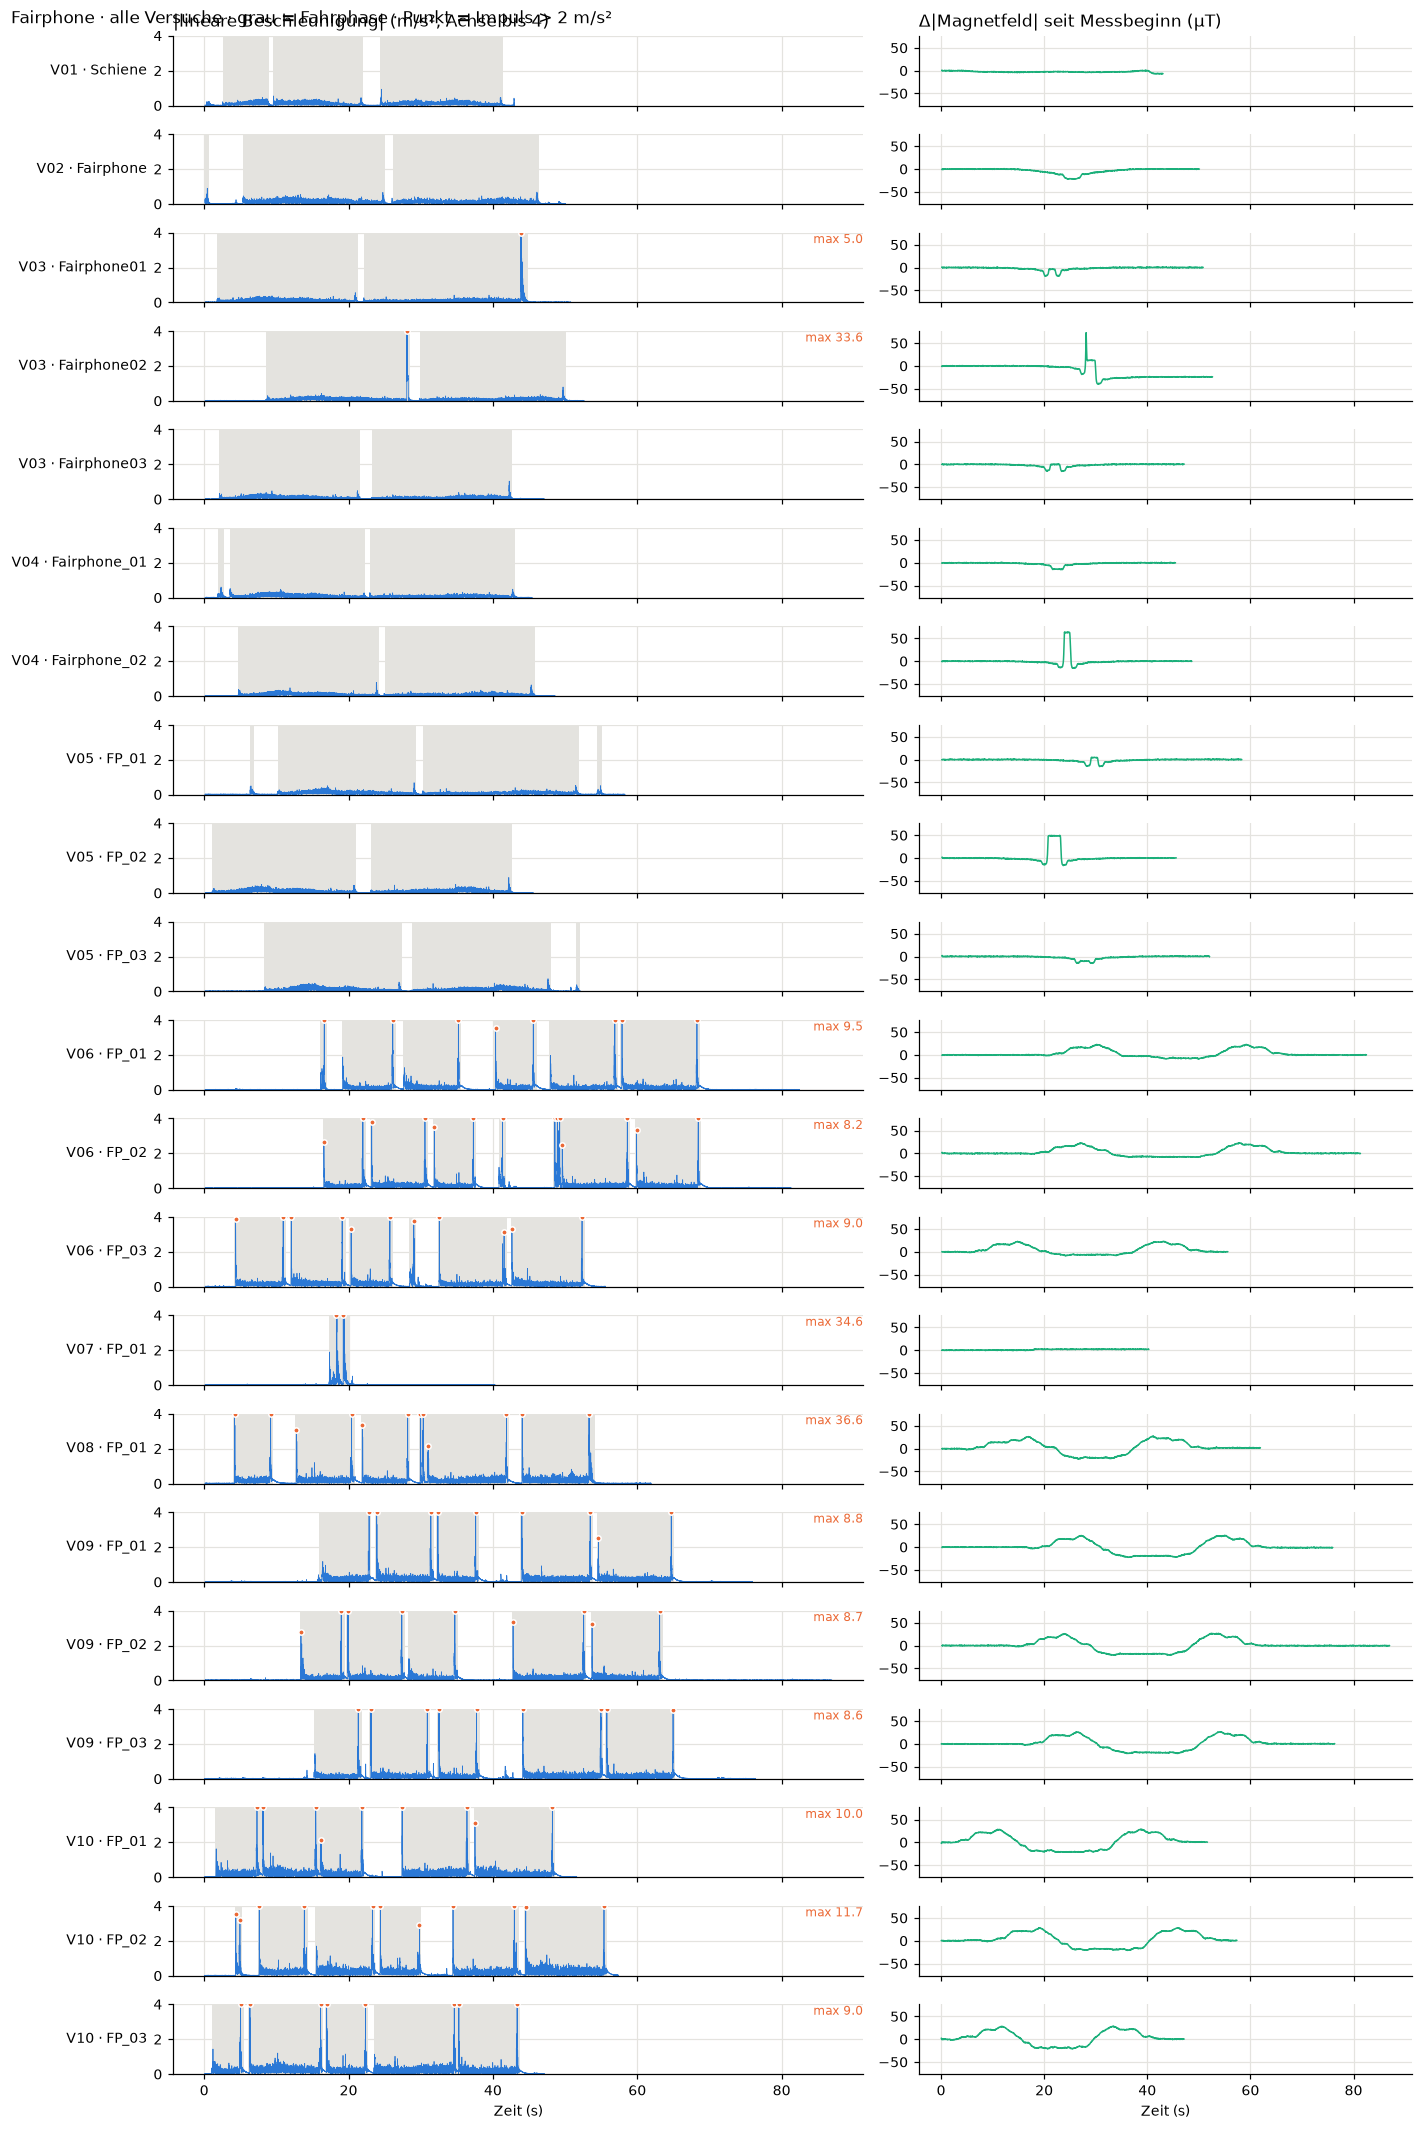

In [5]:
fig = overview('FP', a_max=4)
fig.savefig(FIG / '00_V1_uebersicht_fairphone.png', dpi=150)

### Abb. V2 – iPhone

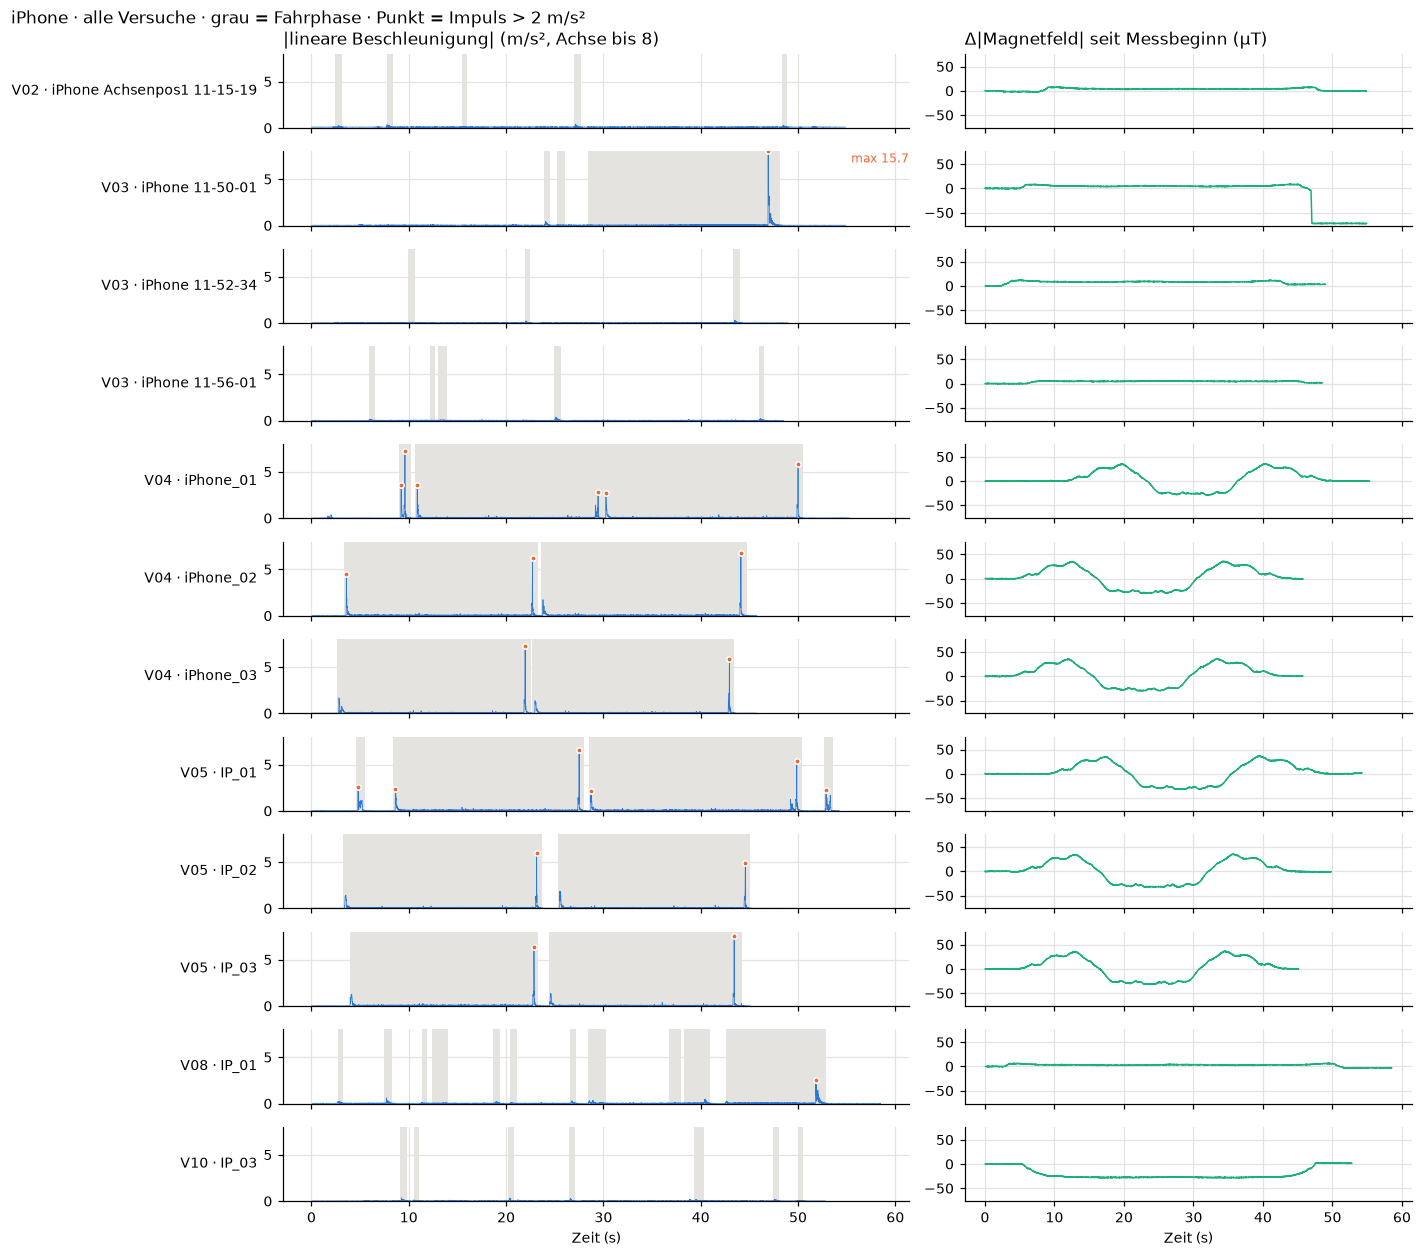

In [6]:
fig = overview('IP', a_max=8)
fig.savefig(FIG / '00_V2_uebersicht_iphone.png', dpi=150)

### Befund A

- **Zwei Fahrmuster auf einen Blick (Fairphone, Abb. V1):**
  - **V01–V05:** zwei lange Fahrphasen (hin und zurück), kaum Impulse. Δ|B| bleibt nahe 0, nur am Wendepunkt ein kurzer Einbruch oder Sprung. → Fairphone **ortsfest am Gestell**, **durchgehende Fahrt** (Gruppe A).
  - **V06, V08–V10:** viele kurze Fahrphasen, an jedem Anfahren und Bremsen ein Impuls. Δ|B| zeigt eine gleichmäßige Welle (≈ ±25 µT, hin und zurück). → Fairphone **auf dem Schlitten**, **Stop-and-go** (Gruppe B).
  - Innerhalb einer Gruppe sehen die Zeilen sehr ähnlich aus. Der Unterschied zwischen den Gruppen ist viel größer als der zwischen den Versuchen einer Gruppe.
- **iPhone (Abb. V2):**
  - **V04 und V05:** fast identische Δ|B|-Wellen (≈ +35 / −30 µT) und zwei lange Fahrphasen mit Bremsimpulsen. → iPhone **auf dem Schlitten**, beide Versuche gleich aufgebaut.
  - **V02, V03, V08, V10:** kaum Signal, Δ|B| ändert sich nur um wenige µT. → iPhone **ortsfest**. Die grauen Abschnitte sind hier Fehlerkennungen, weil die Vibration am ortsfesten iPhone zu schwach für die Fahrphasen-Erkennung ist.
  - In V10 sinkt Δ|B| während der Fahrt um ≈ 25 µT und steigt am Ende wieder. Das ortsfeste iPhone „sieht“ also, wann der Schlitten in der Nähe ist.
- **Sonderfälle:**
  - **V07:** nur ein kurzer Ausschlag bei ≈ 18–20 s (max 34,6 m/s²), Δ|B| flach. → **keine Fahrt**, nur Handhabung.
  - **V03 · Fairphone02:** großer Ruck (33,6 m/s²) bei ≈ 28 s, danach bleibt Δ|B| dauerhaft bei ≈ −25 µT. → Das Handy wurde **bewegt** (stützt Hypothese H2).
  - **V03 · iPhone 11-50-01:** Ruck (15,7 m/s²) bei ≈ 47 s, danach fällt Δ|B| dauerhaft auf ≈ −70 µT. → Handy am Ende der Messung aufgenommen.
- **V10 im Vergleich zu V09:** gleiches Muster (Stop-and-go, gleiche Δ|B|-Welle). Ein Unterschied in der Vibration ist bei dieser Skala nicht direkt zu sehen. Dafür sind die Kennzahlen und Spektren in `V10.ipynb` nötig.
- *Fazit:* Die Abbildungen bestätigen die zwei Gruppen aus den einzelnen Notebooks. Für die Suche nach Maschinenzuständen sollte man **nur innerhalb einer Gruppe und eines Geräts** vergleichen.

## B · Abb. 2 – Spektrum in gleichmäßiger Fahrt

Eine Zeile pro Versuch, darin alle Messungen dieses Versuchs (Farbe = Wiederholung 01/02/03), jeweils auf der Achse mit der meisten Bewegung. Gestrichelt: die drei Frequenzlinien **45,5 Hz**, **86 Hz** und **121,6 Hz**. Messungen ohne Fahrphase über 3 s (ortsfeste iPhones, V07) haben kein Spektrum.

In [7]:
LINES = [45.5, 86, 121.6]     # drive lines seen in the Versuch notebooks

def by_versuch(dev):
    # {'V05': [(name, m), ...]} for one device, in Versuch order
    out = {}
    for label, m in ALL.items():
        if m['dev'] == dev:
            v, name = label.split(' · ', 1)
            out.setdefault(v, []).append((name, m))
    return out

def spectra(dev, f_max):
    # Fig. 2 of all Versuche for one device: one row per Versuch, same log axis in every row
    groups = by_versuch(dev)
    fig, axs = plt.subplots(len(groups), 1, figsize=(13, 1.5 * len(groups) + 0.8), sharex=True, sharey=True, squeeze=False)
    for ax, (v, recs) in zip(axs[:, 0], groups.items()):
        for i, (name, m) in enumerate(recs):
            axis = main_axis(m)
            f, P = spectrum_drive(m, axis)
            if f is not None:
                ax.semilogy(f, P, color=C[i % 3], lw=0.8, label=f'{name} · {axis}')
        for x in LINES:
            if x < f_max:
                ax.axvline(x, color='#888', ls='--', lw=0.7)
        if ax.lines and any(l.get_label()[0] != '_' for l in ax.lines):
            ax.legend(loc='upper right', fontsize=7, ncol=3)
        else:                                                 # no recording with a travel phase > 3 s
            ax.text(0.5, 0.5, 'keine Fahrphase > 3 s', transform=ax.transAxes, ha='center', color='#888')
        ax.set_ylabel(v, rotation=0, ha='right', va='center')
    axs[0, 0].set_xlim(5, f_max)
    axs[-1, 0].set_xlabel('Frequenz (Hz)')
    title = 'Fairphone' if dev == 'FP' else 'iPhone'
    fig.suptitle(f'{title} · Spektrum in gleichmäßiger Fahrt (PSD, (m/s²)²/Hz) · gestrichelt = 45,5 / 86 / 121,6 Hz', x=0.01, ha='left', fontsize=11)
    fig.tight_layout()
    return fig

### Abb. V3 – Fairphone

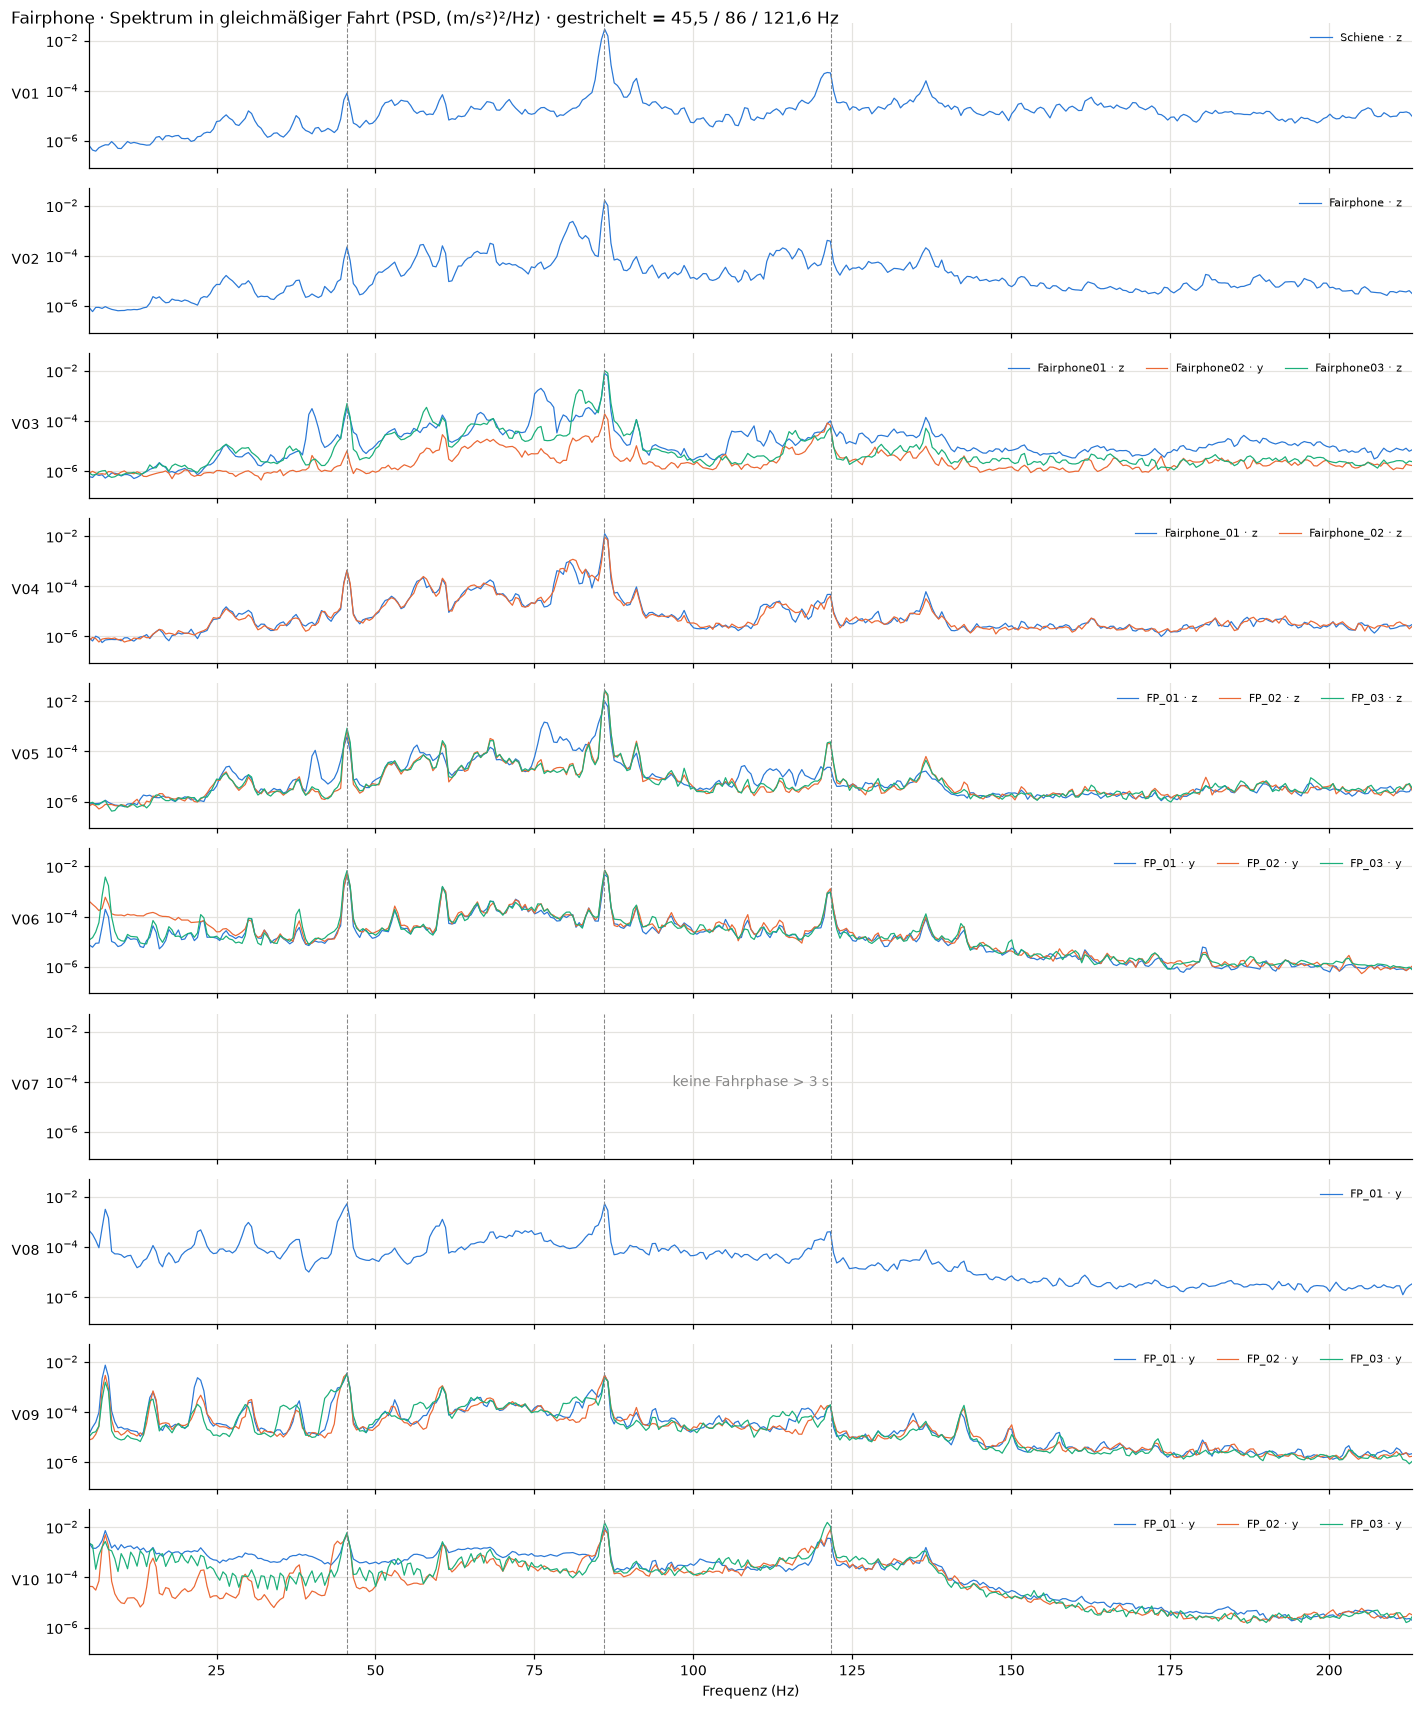

In [8]:
fig = spectra('FP', f_max=213)
fig.savefig(FIG / '00_V3_spektrum_fairphone.png', dpi=150)

### Abb. V4 – iPhone

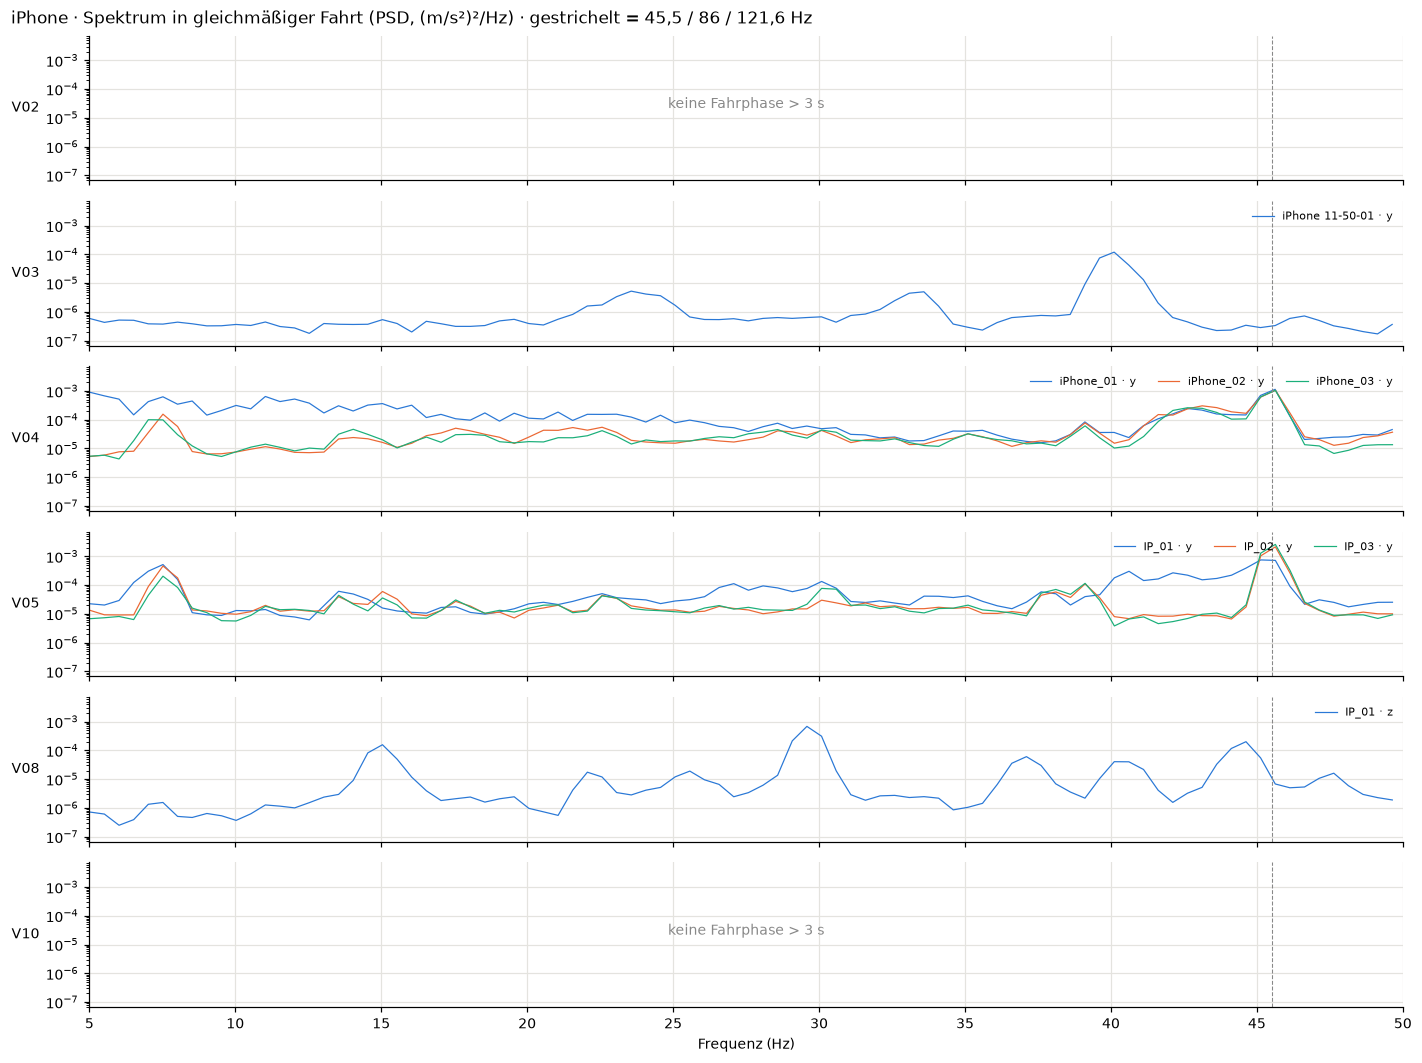

In [9]:
fig = spectra('IP', f_max=50)
fig.savefig(FIG / '00_V4_spektrum_iphone.png', dpi=150)

### Tabelle: Stärke der Frequenzlinien

Für jede Messung mit Spektrum: die stärkste Frequenz über 20 Hz und die Höhe der drei Linien (größter PSD-Wert ± 1,5 Hz um die Linie). Das iPhone erfasst nur bis 50 Hz, daher fehlen dort 86 und 121,6 Hz. Die Fahr-Vibration ist der Median der Hüllkurve während der Fahrphasen (wie in Abschnitt 04 der Versuchs-Notebooks).

In [10]:
def line_height(f, P, f0):
    # Largest PSD value within ±1.5 Hz of a line; NaN if the line is above the device's range
    k = (f > f0 - 1.5) & (f < f0 + 1.5)
    return P[k].max() if k.any() else np.nan

rows = []
for label, m in ALL.items():
    axis = main_axis(m)
    f, P = spectrum_drive(m, axis)
    if f is None:
        continue
    t, env, segs = drive_phases(m)
    moving = np.zeros(len(t), bool)
    for a, b in segs:
        moving |= (t >= a) & (t <= b)
    v, name = label.split(' · ', 1)
    rows.append({'Versuch': v, 'Messung': name, 'Gerät': m['dev'], 'Achse': axis,
                 'Fahr-Vibration (m/s²)': np.median(env[moving]),
                 'stärkste Frequenz (Hz)': f[f > 20][np.argmax(P[f > 20])],
                 **{f'{x} Hz': line_height(f, P, x) for x in LINES}})
lines = pd.DataFrame(rows)
lines.style.format({'Fahr-Vibration (m/s²)': '{:.3f}', 'stärkste Frequenz (Hz)': '{:.1f}',
                    **{f'{x} Hz': '{:.1e}' for x in LINES}}, na_rep='–').hide(axis='index')

Versuch,Messung,Gerät,Achse,Fahr-Vibration (m/s²),stärkste Frequenz (Hz),45.5 Hz,86 Hz,121.6 Hz
V01,Schiene,FP,z,0.125,86.0,8.0e-05,2.8e-02,5.3e-04
V02,Fairphone,FP,z,0.127,86.0,2.3e-04,1.6e-02,4.2e-04
V03,Fairphone01,FP,z,0.092,86.0,3.5e-04,8.0e-03,1.0e-04
V03,Fairphone02,FP,y,0.085,86.0,6.5e-06,1.9e-04,8.4e-05
V03,Fairphone03,FP,z,0.081,86.0,5.0e-04,1.0e-02,5.4e-05
V03,iPhone 11-50-01,IP,y,0.032,40.1,7.2e-07,–,–
V04,Fairphone_01,FP,z,0.077,86.0,4.4e-04,1.2e-02,4.7e-05
V04,Fairphone_02,FP,z,0.076,86.0,4.3e-04,9.1e-03,4.1e-05
V04,iPhone_01,IP,y,0.045,45.6,1.1e-03,–,–
V04,iPhone_02,IP,y,0.045,45.6,1.1e-03,–,–


### Befund B

- **Gruppe A, Fairphone ortsfest (V01–V05, Achse z):**
  - Alle Spektren haben dieselbe Form: **86 Hz ist mit Abstand die stärkste Linie**, darunter ein breiter Buckel zwischen 60 und 85 Hz, 45,5 Hz klein, 121,6 Hz sehr klein.
  - V03, V04 und V05 liegen fast übereinander. → Hier hat sich an der Maschine vermutlich **nichts geändert**.
  - Ausnahme V03 · Fairphone02: Hauptachse y statt z und alles ≈ 10–100× schwächer. Das Handy wurde während der Messung bewegt (siehe Abb. V1), das Spektrum ist nicht vergleichbar.
- **Gruppe B, Fairphone auf dem Schlitten (V06, V08–V10, Achse y):**
  - **V06:** 45,5 Hz und 86 Hz etwa gleich stark, 121,6 Hz deutlich sichtbar (≈ 1·10⁻³).
  - **V08 und V09:** 45,5 Hz ist die stärkste Linie, 86 Hz etwa halb so stark wie in V06, 121,6 Hz ≈ 5× schwächer als in V06. Dazu tieffrequente Linien bei ≈ 7,5 / 15 / 22,5 Hz.
  - **V10:** **121,6 Hz** ist in FP_02 und FP_03 die stärkste Linie (20–80× stärker als in V09). Zusätzlich ist der ganze Bereich ≈ 95–140 Hz angehoben. FP_01 liegt dazwischen.
  - Die drei Wiederholungen eines Versuchs liegen jeweils eng beieinander. Die Unterschiede **zwischen** V06, V08/V09 und V10 sind also echt und kein Zufall einer einzelnen Messung.
- **iPhone (Abb. V4):** Nur V04 und V05 sind vergleichbar (iPhone auf dem Schlitten), beide mit derselben Linie bei 45,5 Hz. Die ortsfesten iPhones liefern kein oder kein brauchbares Spektrum.
- *Interpretation:* Innerhalb von Gruppe B gibt es drei unterscheidbare Spektren: **V06**, **V08/V09** und **V10**. Das passt zu den drei Maschinenzuständen. Wahrscheinliche Wechsel: zwischen V06 und V08 (dazwischen V07 mit Handhabung und 27 min Pause) und zwischen V09 und V10 (21 min Pause). Welcher Zustand der stabile ist, muss das Versuchsprotokoll klären.

## C · Abb. 3 – Vibrationshüllkurve

Eine Zeile pro Versuch, darin alle Messungen dieses Versuchs. Jede Kurve ist so verschoben, dass t = 0 die erste erkannte Bewegung ist. Gleiche Zeit- und Vibrationsachse in allen Zeilen. Die Achse ist bei 0,4 (Fairphone) bzw. 0,25 m/s² (iPhone) abgeschnitten: Größere Ausschläge sind Rucke durch Handhabung (siehe Abb. V1/V2) und würden sonst die normale Fahrt-Vibration unsichtbar machen.

In [11]:
def envelopes(dev, y_max):
    # Fig. 3 of all Versuche for one device: one row per Versuch, curves aligned on the first movement.
    # y_max cuts off handling jerks, otherwise they squash the normal travel level (0.05–0.2 m/s²).
    groups = by_versuch(dev)
    fig, axs = plt.subplots(len(groups), 1, figsize=(13, 1.4 * len(groups) + 0.8), sharex=True, sharey=True, squeeze=False)
    for ax, (v, recs) in zip(axs[:, 0], groups.items()):
        for i, (name, m) in enumerate(recs):
            t, env, segs = drive_phases(m)
            t0 = segs[0][0] if segs else 0                 # no movement: keep the recording time
            ax.plot(t - t0, env, color=C[i % 3], lw=0.8, label=name)
        ax.legend(loc='upper right', fontsize=7, ncol=3)
        ax.set_ylabel(v, rotation=0, ha='right', va='center')
    axs[0, 0].set_ylim(0, y_max)
    axs[-1, 0].set_xlabel('Zeit seit erster Bewegung (s)')
    title = 'Fairphone' if dev == 'FP' else 'iPhone'
    fig.suptitle(f'{title} · Vibrationshüllkurve (m/s², Achse bis {y_max}), ausgerichtet auf erste Bewegung', x=0.01, ha='left', fontsize=11)
    fig.tight_layout()
    return fig

### Abb. V5 – Fairphone

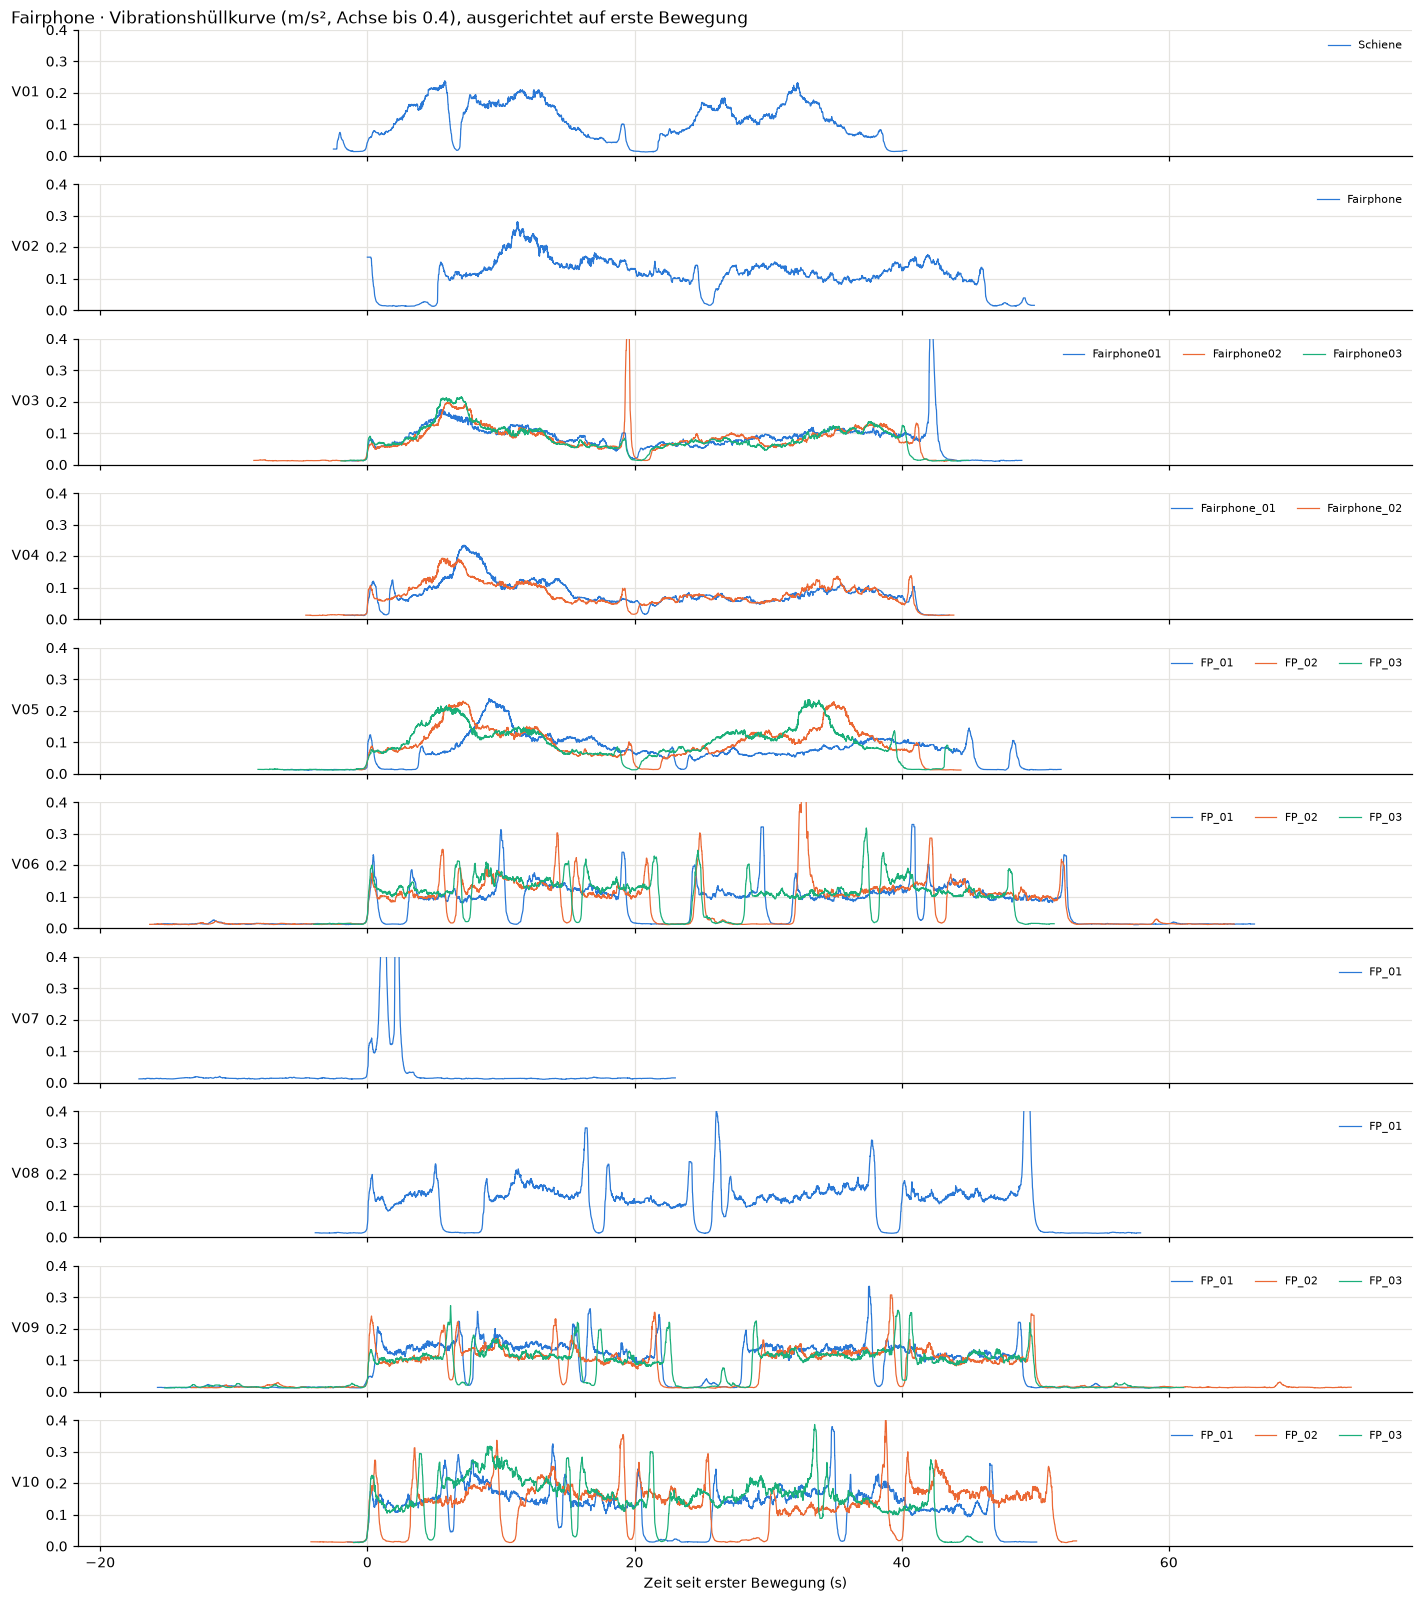

In [12]:
fig = envelopes('FP', y_max=0.4)
fig.savefig(FIG / '00_V5_huellkurve_fairphone.png', dpi=150)

### Abb. V6 – iPhone

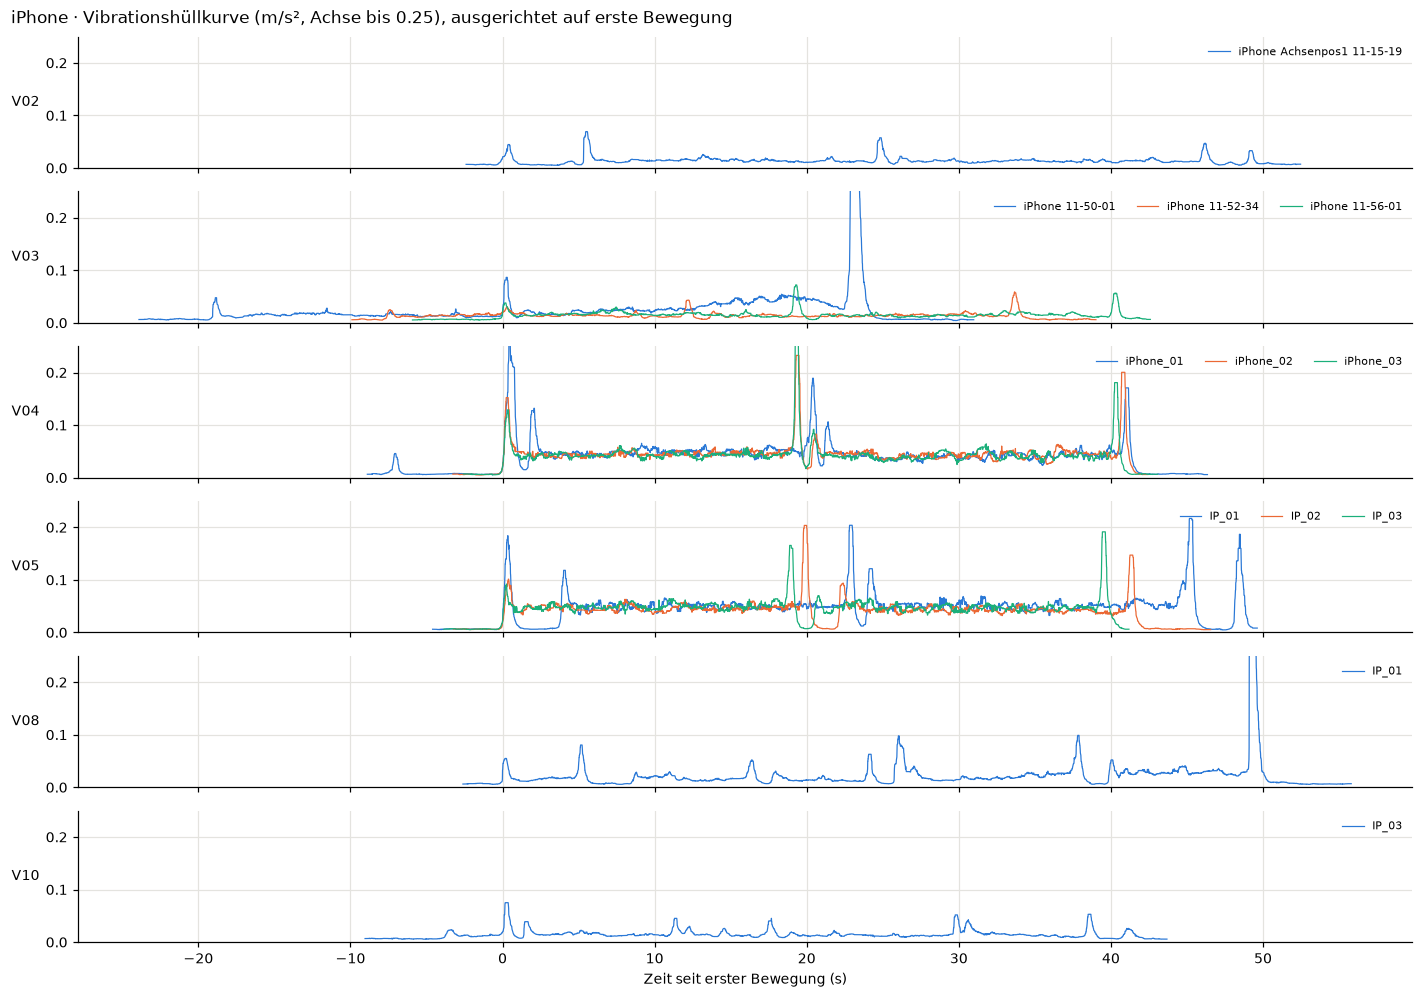

In [13]:
fig = envelopes('IP', y_max=0.25)
fig.savefig(FIG / '00_V6_huellkurve_iphone.png', dpi=150)

### Befund C

- **Gruppe A (Fairphone V01–V05):** zwei flache Bögen (hin und zurück) mit kurzem Einbruch am Wendepunkt bei ≈ 20 s. V03, V04 und V05 haben dieselbe Form und Höhe (≈ 0,05–0,2 m/s²).
- **Gruppe B (Fairphone V06, V08–V10):** Blöcke mit Lücken (Stop-and-go). Das Muster der Halte ist innerhalb eines Versuchs gleich, unterscheidet sich aber zwischen den Versuchen: V09 hat z. B. eine längere Pause in der Mitte (≈ 23–28 s).
- **V10 liegt höher:** Die Fahr-Vibration erreicht ≈ 0,15–0,3 m/s², in V06 und V09 meist ≈ 0,1–0,15 m/s². Das passt zur höheren Fahr-Vibration in der Tabelle (0,15–0,16 statt 0,11–0,13).
- **iPhone:** V04 und V05 (auf dem Schlitten) sind praktisch deckungsgleich, mit konstantem Niveau ≈ 0,05 m/s² und Spitzen nur beim Anfahren und Bremsen. Ortsfeste iPhones (V02, V03, V08, V10) zeigen kaum mehr als das Ruherauschen.
- **Abgeschnittene Ausschläge** (V03, V07, V08) sind Handhabung, keine Maschinenvibration.
- *Fazit:* Die Hüllkurven bestätigen die Spektren: In Gruppe A sind die Versuche gleich. In Gruppe B unterscheidet sich vor allem **V10** deutlich von den anderen.